# 6 · Vessels set the carrying capacity — extension

In the [corrected irrigation model](../corrected/05-diffusion-proliferation-irrigation.ipynb) the vessels hardly affect the tumour: they only raise the growth *rate*, and that rate matters only at the sparse leading edge of the front, where no vessels have formed yet. This notebook changes how the vessels act. **They supply a nutrient (e.g. oxygen), and the local nutrient level sets how many tumour cells the tissue can sustain: the carrying capacity.**

### What this is based on

This follows the mechanism in Rui Travasso's work on tumour angiogenesis:

- In the multiscale tumour-growth and angiogenesis model of Jafari Nivlouei, Soltani, Carvalho, **Travasso**, Salimpour & Shirani (2021), *PLoS Comput Biol* 17(6): e1009081, [doi:10.1371/journal.pcbi.1009081](https://doi.org/10.1371/journal.pcbi.1009081):
  - nutrients are released by the vessels, diffuse through the tissue and are consumed by the cells;
  - cells below a nutrient threshold become hypoxic and stop proliferating, giving a hypoxic and then necrotic tumour core;
  - hypoxic cells secrete VEGF, which recruits new vessels, and once vessels surround the tumour its growth speeds up.
- In **Travasso** et al. (2011), *PLoS ONE* 6(5): e19989, [doi:10.1371/journal.pone.0019989](https://doi.org/10.1371/journal.pone.0019989), hypoxic tissue cells release angiogenic factor "until oxygen is properly delivered to them".

Those papers are cell-based (cellular Potts) and phase-field models. **The continuum equations below are my simplification of that mechanism, not equations from the papers.**

### Model

Three fields on the grid: tumour cell density $n$, nutrient concentration $c$ (1 = well-oxygenated tissue) and vessel density $V$.

$$\frac{\partial c}{\partial t} = D_c\,\nabla^2 c + s\,V\,(1 - c) - \lambda\, n\, c$$

$$\frac{\partial n}{\partial t} = D\,\nabla^2 n + \alpha_0\, n\,\frac{K - n}{N_{\max}}, \qquad K = N_{\max}\, c$$

$$\frac{\partial V}{\partial t} = \beta(x)\, n\,(1 - c)\left(1 - \frac{V}{V_{\max}}\right)$$

- **Nutrient:** vessels supply it (rate $s$, proportional to $V$), it diffuses ($D_c$), and tumour cells consume it ($\lambda$). The diffusion length $L = \sqrt{D_c/\lambda}$ is how far nutrient reaches into a dense tumour.
- **Tumour:** logistic growth towards a **local carrying capacity $K = N_{\max}\,c$**. Where nutrient is scarce, $n > K$ and the growth term turns negative, so cells die. This stands in for the hypoxic/necrotic core.
- **Vessels:** grow where there are **hypoxic** tumour cells, i.e. tumour present ($n$) *and* nutrient low ($1 - c$). This stands in for VEGF secretion by hypoxic cells. It replaces the original $\beta n$, which grew vessels wherever there was tumour, hypoxic or not.

**Experiment.** Angiogenesis is blocked on the left half ($\beta = 0$, as under anti-VEGF treatment) and active on the right half ($\beta = 0.5$). A control run with $\beta = 0$ everywhere shows what the tumour does without new vessels.

**Time scales.** Oxygen equilibrates in seconds to minutes, while tumour cells divide over about a day. So the nutrient is updated with 20 short sub-steps per tumour time step, which keeps it close to equilibrium.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
# Grid and tumour (same as model 5)
l = 200
A = 0.05
σ1, σ2, σ3 = 15, 25, 12
delta_t = 0.1
delta_x = 1
D = 0.2
Alpha_zero = 1
N_Max = 1
cutoff = 1e-3

# Vessels
V_max = 4
beta_left = 0.0      # angiogenesis blocked
beta_right = 0.5     # angiogenesis active

# Nutrient (illustrative values in grid units, not calibrated to tissue)
D_c = 40                     # nutrient diffusion
L = 8                        # nutrient penetration length into dense tumour, in grid cells
lam = D_c / L**2             # consumption rate per tumour cell
s = 0.1 * lam                # supply rate per unit vessel density
substeps = 20                # nutrient sub-steps per tumour step
delta_t_c = delta_t / substeps

num_steps = 1000
save_steps = [100, 300, 500, 700, 1000]

# Explicit-scheme stability checks (2D, 5-point stencil)
assert D * delta_t / delta_x**2 <= 0.25
assert D_c * delta_t_c / delta_x**2 <= 0.25
assert (s * V_max + lam * N_Max) * delta_t_c < 1

In [3]:
def laplacian(f):
    """5-point Laplacian with periodic boundaries (as in the other notebooks)."""
    return (np.roll(f, 1, axis=0) + np.roll(f, -1, axis=0)
            + np.roll(f, 1, axis=1) + np.roll(f, -1, axis=1) - 4 * f) / delta_x**2

# Same three Gaussian regions as the other notebooks, with the cutoff
i, j = np.meshgrid(np.arange(l), np.arange(l), indexing="ij")

def gaussian(ci, cj, sigma):
    return A * np.exp(-((i - ci)**2 + (j - cj)**2) / (2 * sigma**2))

n_initial = gaussian(l/2, l/2 - 10, σ1) + gaussian(l/2, 3*l/4 - 30, σ2) + gaussian(2*l/5, 3*l/5 - 10, σ3)
n_initial[n_initial < cutoff] = 0.0

In [4]:
def simulate(beta_left, beta_right):
    """Run the model. Returns snapshots and the mean tumour density over time
    in two patches of the same size, one in each half of the grid."""
    n = n_initial.copy()
    c = np.ones((l, l))               # tissue starts well oxygenated
    V = np.ones((l, l))               # uniform initial vessel density
    Beta = np.zeros((l, l))
    Beta[:, : l // 2] = beta_left
    Beta[:, l // 2 :] = beta_right

    left_patch = (slice(60, 140), slice(20, 80))
    right_patch = (slice(60, 140), slice(120, 180))
    snapshots, history = {}, {"t": [], "left": [], "right": []}

    for step in range(1, num_steps + 1):
        for _ in range(substeps):                         # fast nutrient
            c = c + delta_t_c * (D_c * laplacian(c) + s * V * (1 - c) - lam * n * c)
        K = N_Max * c                                     # local carrying capacity
        n_next = n + delta_t * (D * laplacian(n) + Alpha_zero * n * (K - n) / N_Max)
        V_next = V + delta_t * Beta * n * (1 - c) * (1 - V / V_max)
        n, V = n_next, V_next

        if step % 10 == 0:
            history["t"].append(step * delta_t)
            history["left"].append(n[left_patch].mean())
            history["right"].append(n[right_patch].mean())
        if step in save_steps:
            snapshots[step] = (n.copy(), c.copy(), V.copy())
    return snapshots, history

control, control_history = simulate(0.0, 0.0)
angio, angio_history = simulate(beta_left, beta_right)

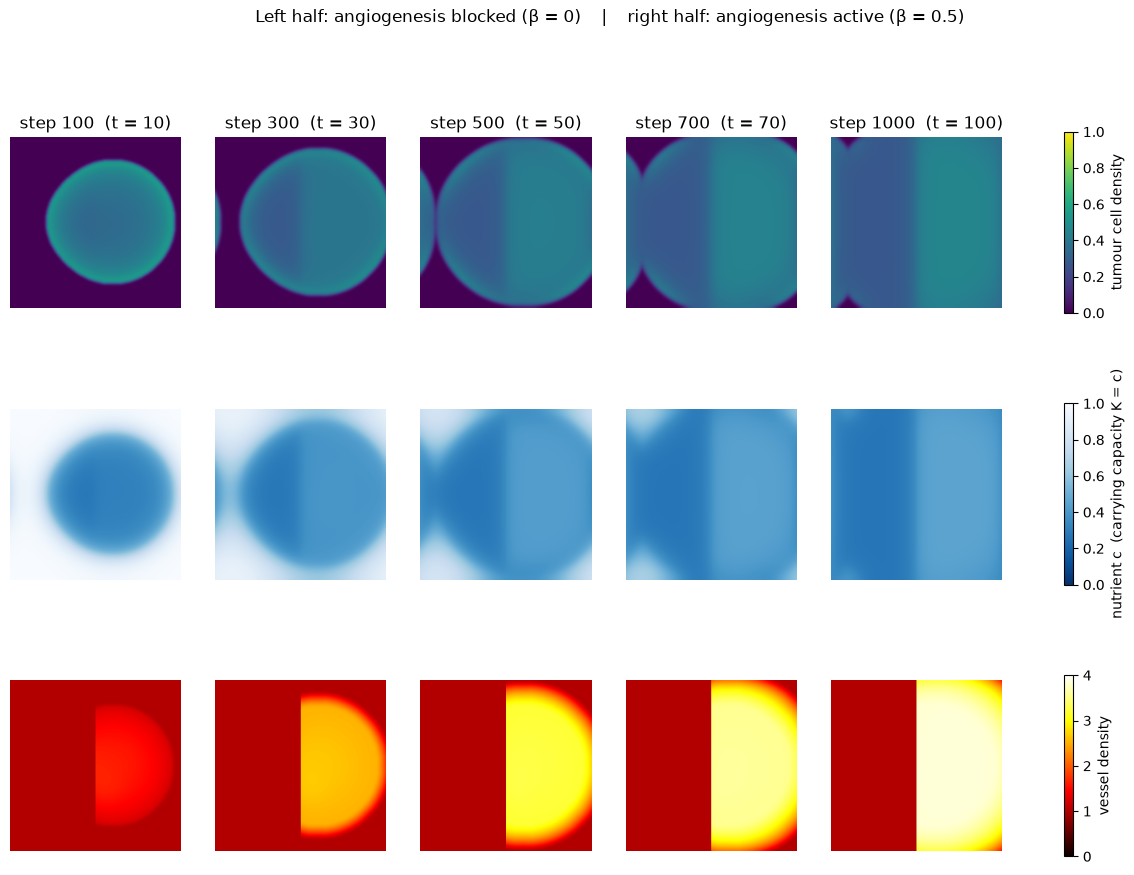

In [5]:
fig, axes = plt.subplots(3, len(save_steps), figsize=(3.2 * len(save_steps), 10))
rows = [("tumour cell density", "viridis", 0, N_Max),
        ("nutrient c  (carrying capacity K = c)", "Blues_r", 0, 1),
        ("vessel density", "hot", 0, V_max)]
for col, step in enumerate(save_steps):
    for row, field in enumerate(angio[step]):
        label, cmap, vmin, vmax = rows[row]
        im = axes[row, col].imshow(field, origin="lower", cmap=cmap, vmin=vmin, vmax=vmax)
        if col == len(save_steps) - 1:
            fig.colorbar(im, ax=axes[row, :], shrink=0.8, label=label)
    axes[0, col].set_title(f"step {step}  (t = {step * delta_t:g})")
for ax in axes.flat:
    ax.axis("off")
fig.suptitle("Left half: angiogenesis blocked (β = 0)    |    right half: angiogenesis active (β = 0.5)")
plt.show()

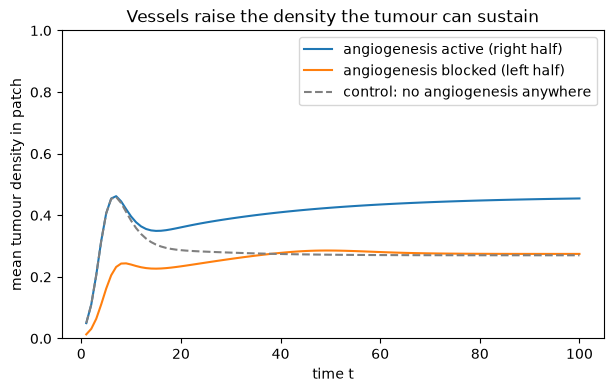

t = 100: mean density, angiogenesis active  0.45
t = 100: mean density, angiogenesis blocked 0.27
t = 100: mean density, control (right half)  0.27


In [6]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(angio_history["t"], angio_history["right"], label="angiogenesis active (right half)")
ax.plot(angio_history["t"], angio_history["left"], label="angiogenesis blocked (left half)")
ax.plot(control_history["t"], control_history["right"], "--", color="grey", label="control: no angiogenesis anywhere")
ax.set_xlabel("time t")
ax.set_ylabel("mean tumour density in patch")
ax.set_ylim(0, N_Max)
ax.legend()
ax.set_title("Vessels raise the density the tumour can sustain")
plt.show()

final = num_steps
print(f"t = {final * delta_t:g}: mean density, angiogenesis active  {angio_history['right'][-1]:.2f}")
print(f"t = {final * delta_t:g}: mean density, angiogenesis blocked {angio_history['left'][-1]:.2f}")
print(f"t = {final * delta_t:g}: mean density, control (right half)  {control_history['right'][-1]:.2f}")

**Reading the result.**

- **Hypoxic core.** Once the tumour is larger than the nutrient penetration length $L$, its interior runs short of nutrient. The local carrying capacity drops, cells die back, and only a rim near the well-fed tissue stays dense. This is the hypoxic, then necrotic, core described by Jafari Nivlouei et al. (2021).
- **Angiogenesis rescues the tumour.** On the right half, hypoxic tumour cells recruit vessels. More vessels supply more nutrient, which raises the carrying capacity, so the tumour there becomes clearly denser than on the blocked left half. In the control run, with no angiogenesis anywhere, both halves stay at the low, nutrient-limited density.
- **Vessel growth follows hypoxia.** Vessels grow in proportion to $1 - c$, so growth is strongest where the tumour is most starved and weakens as nutrient recovers. This is the feedback in Travasso et al. (2011), where hypoxic cells release factor "until oxygen is properly delivered to them". With these parameters the nutrient on the right only recovers to about 0.46 (0.27 on the blocked left), so the tumour stays partly hypoxic and the vessels keep growing until they approach $V_{\max}$. The tumour density settles at that carrying capacity: 0.45 vs 0.27.

**Limitations.**

- This is a continuum caricature of cell-based models: there is no VEGF field, no individual vessels or tip cells, and no blood flow.
- Parameters are in grid units and chosen for illustration, not calibrated to tissue.
- As in the other notebooks, the tumour front is only about $\sqrt{D/\alpha_0} \approx 0.45$ grid cells wide, so front speeds are partly a grid effect.
- Boundaries are periodic.